Saving software_quality_insight_dataset.zip to software_quality_insight_dataset.zip
DATASET OVERVIEW

modules: 10 rows, 4 columns


,module,component,language,size
0,AUTH,Authentication,Java,4200
1,PAY,Payment,Java,6100
2,API,API Gateway,Python,3500
3,DB,Database,Java,5200
4,UI,User Interface,TypeScript,4800



metrics: 52 rows, 6 columns


,module,release,complexity,coupling,churn,test_coverage
0,AUTH,v1.0,15.0,NaN,97,0.73
1,PAY,v1.0,31.0,0.58,181,0.57
2,API,v1.0,28.0,0.55,161,0.50
3,DB,v1.0,33.0,0.64,145,0.64
4,UI,v1.0,18.0,0.35,130,0.67



defects: 51 rows, 4 columns


...


releases: 50 rows, 3 columns


,module,version,release_date
0,AUTH,v1.0,2022-02-15
1,PAY,v1.0,2022-02-15
2,API,v1.0,2022-02-15
3,DB,v1.0,2022-02-15
4,UI,v1.0,2022-02-15


,dataset,column,dtype,missing,missing_percent,unique_values
0,modules,module,object,0,0.00,10
1,modules,component,object,0,0.00,10
2,modules,language,object,0,0.00,4
3,modules,size,int64,0,0.00,10
4,metrics,module,object,0,0.00,11
5,metrics,release,object,0,0.00,5
6,metrics,complexity,float64,1,1.92,24
7,metrics,coupling,float64,1,1.92,35
8,metrics,churn,int64,0,0.00,45
9,metrics,test_coverage,float64,1,1.92,31



EXACT DUPLICATE ROWS
modules : 0
metrics : 0
defects : 0
commits : 0
releases : 0

DUPLICATE MODULE-RELEASE KEYS
metrics : 4
defects : 0
commits : 0
releases : 0

IQR lower bound: 4.25
IQR upper bound: 38.25
Potential complexity outliers: 1


,module,release,complexity,coupling,churn,test_coverage
21,PAY,v3.0,185.0,0.61,211,0.62


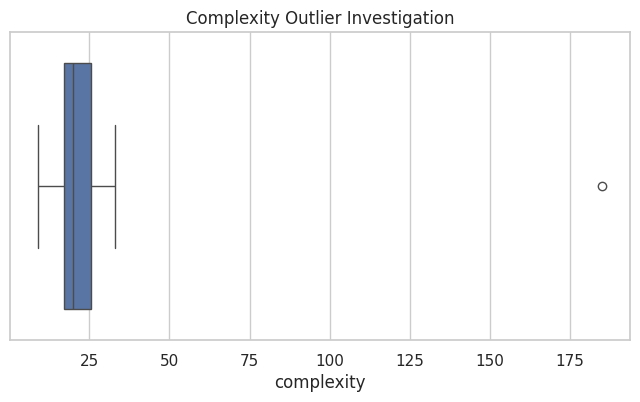


Unmatched module records: 1


,source_dataset,module,release,defect_count,severity
0,defects,LEGACYMOD,v3.0,7,High


,column,missing_before,median_used,missing_after
0,complexity,1,20.000,0
1,coupling,0,0.445,0
2,churn,0,137.500,0
3,test_coverage,1,0.740,0



MERGED DATASET
Shape: (50, 15)


,module,release,complexity,coupling,churn,test_coverage,component,language,size,defect_count,severity,commit_count,contributors,changed_lines,release_date
0,PAY,v1.0,31.0,0.58,181,0.57,Payment,Java,6100,10,High,30,5,238,2022-02-15
1,API,v1.0,28.0,0.55,161,0.50,API Gateway,Python,3500,9,High,27,5,218,2022-02-15
2,DB,v1.0,33.0,0.64,145,0.64,Database,Java,5200,8,High,24,4,198,2022-02-15
3,UI,v1.0,18.0,0.35,130,0.67,User Interface,TypeScript,4800,7,Medium,23,4,183,2022-02-15
4,NOTIFY,v1.0,11.0,0.26,49,0.81,Notification,Python,2100,5,Medium,12,1,118,2022-02-15
5,REPORT,v1.0,20.0,0.43,89,0.70,Reporting,Java,3900,6,Medium,17,1,158,2022-02-15
6,SEARCH,v1.0,22.0,0.49,119,0.62,Search,Python,3000,6,Medium,21,1,188,2022-02-15
7,FILES,v1.0,17.0,0.38,78,0.76,File Service,Go,2700,6,Medium,15,7,143,2022-02-15
8,ADMIN,v1.0,15.0,0.33,63,0.78,Admin Portal,TypeScript,3300,4,Low,13,7,128,2022-02-15
9,AUTH,v2.0,18.0,0.40,113,0.76,Authentication,Java,4200,7,Medium,17,7,171,2023-04-15


,missing_after_merge
module,0
release,0
complexity,0
coupling,0
churn,0
test_coverage,0
component,0
language,0
size,0
defect_count,0



NOTEBOOK 1 COMPLETED
Saved: data/processed/software_quality_cleaned.csv
Saved data-quality and outlier audit reports.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:

# ============================================================
# NOTEBOOK 1: DATA UNDERSTANDING AND CLEANING
# Use Case 28 - Software Quality Insight
# ============================================================

import os
import zipfile
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from google.colab import files

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

# 1. Upload the dataset ZIP
uploaded = files.upload()
zip_file = next(
    (name for name in uploaded if name.lower().endswith(".zip")),
    None
)
if zip_file is None:
    raise ValueError("Please upload software_quality_insight_dataset.zip")

# 2. Extract files
ROOT = "/content/Software-Quality-Insight"
RAW = f"{ROOT}/data/raw"
OUT = f"{ROOT}/data/processed"
PLOTS = f"{ROOT}/visualizations"

for folder in [RAW, OUT, PLOTS]:
    os.makedirs(folder, exist_ok=True)

with zipfile.ZipFile(zip_file, "r") as z:
    for member in z.namelist():
        if member.lower().endswith(".csv"):
            destination = os.path.join(RAW, os.path.basename(member))
            with z.open(member) as src, open(destination, "wb") as dst:
                dst.write(src.read())

# 3. Load all datasets
modules = pd.read_csv(f"{RAW}/modules.csv")
metrics = pd.read_csv(f"{RAW}/metrics.csv")
defects = pd.read_csv(f"{RAW}/defects.csv")
commits = pd.read_csv(f"{RAW}/commits.csv")
releases = pd.read_csv(f"{RAW}/releases.csv")

datasets = {
    "modules": modules,
    "metrics": metrics,
    "defects": defects,
    "commits": commits,
    "releases": releases
}

print("DATASET OVERVIEW")
for name, df in datasets.items():
    print(f"\n{name}: {df.shape[0]} rows, {df.shape[1]} columns")
    display(df.head())

# 4. Inspect schema and missing values
schema_rows = []
for name, df in datasets.items():
    for col in df.columns:
        schema_rows.append({
            "dataset": name,
            "column": col,
            "dtype": str(df[col].dtype),
            "missing": int(df[col].isna().sum()),
            "missing_percent": round(df[col].isna().mean() * 100, 2),
            "unique_values": int(df[col].nunique())
        })

schema = pd.DataFrame(schema_rows)
display(schema)
schema.to_csv(f"{OUT}/schema_report.csv", index=False)

# 5. Check exact duplicates
print("\nEXACT DUPLICATE ROWS")
for name, df in datasets.items():
    print(name, ":", df.duplicated().sum())

# 6. Normalize module names
def normalize_module(series):
    s = series.astype("string").str.strip().str.upper()
    aliases = {
        "PAYMENT": "PAY",
        "AUTHENTICATION": "AUTH",
        "API GATEWAY": "API",
        "DATABASE": "DB",
        "USER INTERFACE": "UI",
        "NOTIFICATION": "NOTIFY",
        "REPORTING": "REPORT",
        "FILE SERVICE": "FILES",
        "ADMIN PORTAL": "ADMIN"
    }
    return s.replace(aliases)

for df in datasets.values():
    if "module" in df.columns:
        df["module"] = normalize_module(df["module"])

for df in [metrics, defects, commits]:
    df["release"] = df["release"].astype(str).str.strip().str.lower()

releases["version"] = releases["version"].astype(str).str.strip().str.lower()
releases["release_date"] = pd.to_datetime(
    releases["release_date"], errors="coerce"
)

# 7. Convert numeric columns
numeric_cols = {
    "modules": ["size"],
    "metrics": ["complexity", "coupling", "churn", "test_coverage"],
    "defects": ["defect_count"],
    "commits": ["commit_count", "contributors", "changed_lines"]
}
for name, cols in numeric_cols.items():
    for col in cols:
        datasets[name][col] = pd.to_numeric(
            datasets[name][col], errors="coerce"
        )

# 8. Identify duplicate module-release keys
print("\nDUPLICATE MODULE-RELEASE KEYS")
for name, df, keys in [
    ("metrics", metrics, ["module", "release"]),
    ("defects", defects, ["module", "release"]),
    ("commits", commits, ["module", "release"]),
    ("releases", releases, ["module", "version"])
]:
    print(name, ":", df.duplicated(keys, keep=False).sum())

# 9. Investigate complexity outliers using IQR
q1 = metrics["complexity"].quantile(0.25)
q3 = metrics["complexity"].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = metrics[
    (metrics["complexity"] < lower) |
    (metrics["complexity"] > upper)
].copy()

print("\nIQR lower bound:", lower)
print("IQR upper bound:", upper)
print("Potential complexity outliers:", len(outliers))
display(outliers)

plt.figure(figsize=(8, 4))
sns.boxplot(x=metrics["complexity"])
plt.title("Complexity Outlier Investigation")
plt.savefig(f"{PLOTS}/complexity_outlier_boxplot.png",
            dpi=150, bbox_inches="tight")
plt.show()

# 10. Resolve duplicate metrics keys.
# Keep the row with the most complete metric values.
metric_fields = ["complexity", "coupling", "churn", "test_coverage"]
metrics["_completeness"] = metrics[metric_fields].notna().sum(axis=1)
metrics_clean = (
    metrics.sort_values("_completeness", ascending=False, kind="stable")
    .drop_duplicates(["module", "release"], keep="first")
    .drop(columns="_completeness")
    .copy()
)

# Aggregate duplicate defect records rather than silently dropping counts.
defects_clean = defects.drop_duplicates().groupby(
    ["module", "release"], as_index=False
).agg(
    defect_count=("defect_count", "sum"),
    severity=("severity", lambda x:
        "High" if (x == "High").any()
        else ("Medium" if (x == "Medium").any() else "Low"))
)

# Aggregate repeated commit activity.
commits_clean = commits.groupby(
    ["module", "release"], as_index=False
).agg(
    commit_count=("commit_count", "sum"),
    contributors=("contributors", "max"),
    changed_lines=("changed_lines", "sum")
)

modules_clean = modules.drop_duplicates("module", keep="first").copy()
releases_clean = (
    releases.sort_values("release_date", na_position="last")
    .drop_duplicates(["module", "version"], keep="first")
    .copy()
)

# 11. Identify unmatched records
catalogue = set(modules_clean["module"].dropna())
unmatched = []

for name, df in [
    ("metrics", metrics_clean),
    ("defects", defects_clean),
    ("commits", commits_clean),
    ("releases", releases_clean)
]:
    bad = df[~df["module"].isin(catalogue)].copy()
    if not bad.empty:
        bad.insert(0, "source_dataset", name)
        unmatched.append(bad)

unmatched_df = (
    pd.concat(unmatched, ignore_index=True, sort=False)
    if unmatched else pd.DataFrame()
)
print("\nUnmatched module records:", len(unmatched_df))
display(unmatched_df)
unmatched_df.to_csv(f"{OUT}/unmatched_module_records.csv", index=False)

# Keep unmatched records in the audit file; exclude from main analytical table.
metrics_clean = metrics_clean[metrics_clean["module"].isin(catalogue)].copy()
defects_clean = defects_clean[defects_clean["module"].isin(catalogue)].copy()
commits_clean = commits_clean[commits_clean["module"].isin(catalogue)].copy()
releases_clean = releases_clean[releases_clean["module"].isin(catalogue)].copy()

# 12. Handle missing metric values using medians.
# Record the values used so the cleaning is transparent.
imputation_log = []
for col in metric_fields:
    missing_before = int(metrics_clean[col].isna().sum())
    median = metrics_clean[col].median()
    if pd.notna(median):
        metrics_clean[col] = metrics_clean[col].fillna(median)
    imputation_log.append({
        "column": col,
        "missing_before": missing_before,
        "median_used": median,
        "missing_after": int(metrics_clean[col].isna().sum())
    })

imputation_report = pd.DataFrame(imputation_log)
display(imputation_report)
imputation_report.to_csv(f"{OUT}/imputation_report.csv", index=False)

# 13. Merge at module-release level
merged = metrics_clean.merge(
    modules_clean[["module", "component", "language", "size"]],
    on="module", how="left", validate="many_to_one"
)

merged = merged.merge(
    defects_clean,
    on=["module", "release"], how="left", validate="one_to_one"
)

merged = merged.merge(
    commits_clean,
    on=["module", "release"], how="left", validate="one_to_one"
)

release_lookup = releases_clean.rename(columns={"version": "release"})
merged = merged.merge(
    release_lookup[["module", "release", "release_date"]],
    on=["module", "release"], how="left", validate="many_to_one"
)

# Do not automatically replace missing defect counts with zero.
print("\nMERGED DATASET")
print("Shape:", merged.shape)
display(merged.head(10))
display(merged.isna().sum().to_frame("missing_after_merge"))

# 14. Export cleaned dataset and audit reports
merged.to_csv(f"{OUT}/software_quality_cleaned.csv", index=False)
outliers.to_csv(f"{OUT}/complexity_outlier_review.csv", index=False)

quality_report = {
    "input_rows": {k: int(len(v)) for k, v in datasets.items()},
    "cleaned_rows": int(len(merged)),
    "cleaned_columns": int(merged.shape[1]),
    "potential_complexity_outliers": int(len(outliers)),
    "unmatched_module_rows": int(len(unmatched_df)),
    "missing_values_after_merge": {
        k: int(v) for k, v in merged.isna().sum().items()
    }
}
with open(f"{OUT}/data_quality_report.json", "w") as f:
    json.dump(quality_report, f, indent=2, default=str)

print("\nNOTEBOOK 1 COMPLETED")
print("Saved: data/processed/software_quality_cleaned.csv")
print("Saved data-quality and outlier audit reports.")

# 15. Download the cleaned data
files.download(f"{OUT}/software_quality_cleaned.csv")
